In [1]:
import os
import scanpy as sc
import matplotlib.pyplot as plt

In [ ]:
pth = os.path.join('..', '..')
pth_in = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'neuroblastoma')
pth_out = os.path.join(pth, 'figures', 'neuroblastoma')

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_in, 'processed.h5ad'))
adata

AnnData object with n_obs × n_vars = 5101 × 19695
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'percent.RPL', 'percent.RPS', 'S.Score', 'G2M.Score', 'Phase', 'CC.Difference', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.0.8', 'seurat_clusters', 'ident', 'celltype'
    uns: 'Phase_colors', 'X_name', 'celltype_colors', 'ident_colors', 'log1p'
    obsm: 'UMAP.GRAPH', 'X_pca', 'X_umap'
    layers: 'logcounts'

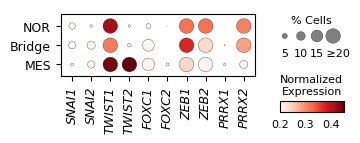

In [4]:
g_plt = ['SNAI1', 'SNAI2', 'TWIST1', 'TWIST2', 'FOXC1',
         'FOXC2', 'ZEB1', 'ZEB2', 'PRRX1', 'PRRX2']
cat = {'NOR' : 'NOR', 'NOR/MES' : 'Bridge', 'MES' : 'MES'}

# expression dotplot
fs1, fs2 = 9, 8
dp = sc.pl.dotplot(adata, g_plt, 'celltype',
                   categories_order = list(cat.keys()),
                   dot_max = .2, vmin = .2,
                   figsize = (3.65, .8),
                   return_fig = True,
                   show = False)

dp.style(largest_dot = 110,
         x_padding = .6,
         y_padding = .6)
dp.legend(width = .9)

ax = dp.get_axes()
ax_main = ax['mainplot_ax']
ax_size = ax['size_legend_ax']
cax = ax['color_legend_ax']

ax_size.set_title('% Cells', size = fs2, pad = -10)
ax_size.tick_params('x', size = 0, labelsize = fs2, pad = 2)
ax_size.set_xticklabels(['5', '10', '15', '   ≥20'])
cax.set_title('Normalized\nExpression', size = fs2, pad = 5)
cax.set_xticks([.2, .3, .4])
cax.tick_params('x', size = 0, labelsize = fs2, pad = 5)

pos_main = ax_main.get_position()
pos_size = ax_size.get_position()
pos_color = cax.get_position()

ax_size.set_position([pos_size.x0,
                      pos_main.y0 + .5 * pos_main.height,
                      pos_size.width,
                      2.5 * pos_size.height])

cax.set_position([pos_color.x0,
                  pos_main.y0 - .58 * pos_main.height,
                  pos_color.width,
                  2.5 * pos_color.height])

ax_main.set_xticklabels(ax_main.get_xticklabels(),
                        fontsize = fs1,
                        fontstyle = 'italic')

ax_main.set_yticklabels(list(cat.values()),
                        fontsize = fs1)

fn = os.path.join(pth_out, 'expression.pdf')
plt.savefig(fn, bbox_inches = 'tight')